In [1]:
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 75.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]


In [2]:
!pip install pylatexenc

In [3]:
from qiskit import QuantumCircuit

In [4]:
import matplotlib as mpl
import numpy as np

Generate a random graph on $n$ vertices, with each edge included (independently) with probability $p$. For now, we take every edge to have weight 1, although this could be generalized.

In [5]:
# n = number of vertices
n = 6

# p = probability of including each edge (independently)
p = 0.6

Generate the adjacency matrix. In general, for an undirected graph adjacency matrices are defined as symmetric square matrices with diagonal entries equal to 0. But for the purposes of this project we may equivalently take the strictly upper triangular half of such a matrix for convenience.

In [6]:
# First generate a random n by n matrix (as an array)
rand_matrix = np.random.rand(n,n)

# Extract the (strictly) upper triangular portion
prob_matrix = np.triu(rand_matrix, k=1)

# Interpret entries as edges with probability p
adj_matrix = np.zeros((n,n))

# For simplicity, we only work in the weight 1 case
# But, this could be generalized at this step without further changes to the code below
adj_matrix[ prob_matrix > 1-p] = 1

# List positions of 1s, which tells us the pairs of adjacent vertices
adj_vertices = np.argwhere(adj_matrix == 1)

# There is some redundancy here, but I choose to keep it for the sake of clarity

In [7]:
print(prob_matrix)

[[0.         0.85591588 0.0553725  0.22992649 0.18597531 0.06294636]
 [0.         0.         0.24079683 0.89491182 0.89665922 0.71418147]
 [0.         0.         0.         0.55955355 0.08472235 0.61984108]
 [0.         0.         0.         0.         0.44130934 0.11969569]
 [0.         0.         0.         0.         0.         0.57316069]
 [0.         0.         0.         0.         0.         0.        ]]


In [8]:
print(adj_matrix)

[[0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 0. 1.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0.]]


In [9]:
print(adj_vertices)

[[0 1]
 [1 3]
 [1 4]
 [1 5]
 [2 3]
 [2 5]
 [3 4]
 [4 5]]


In [10]:
import rustworkx as rx
from rustworkx.visualization import mpl_draw

In [11]:
G = rx.PyGraph()
G.add_nodes_from(range(n))
edges = []

# Get edges (start, end, weight)
for edge in adj_vertices:
  edges.append((edge[0],edge[1],adj_matrix[edge[0],edge[1]]))

G.add_edges_from(edges)

EdgeIndices[0, 1, 2, 3, 4, 5, 6, 7]

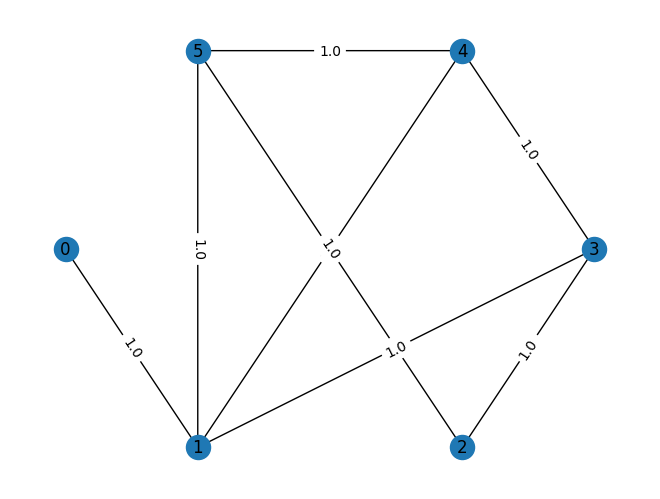

In [12]:
# Draw the graph
mpl_draw(G, pos=rx.shell_layout(G), with_labels=True, edge_labels=str)

Create the appropriate Hamiltonian for our particular graph. We want a sum of Pauli strings, one for each edge, with a $Z$ gate applied to the qubits of the same index as the ends of the edge.  

Note that indexing is reversed; the 0-th qubit corresponds to the final entry of the string.

The desired "cut value" will differ from the ground state of the Hamiltonian we construct by a simple transformation (depending only on the graph $G$), which we shall take into account later.

In [13]:
pstrings = []

for edge in edges:
  gates = ['I'] * n
  gates[n - 1 - edge[0]] = 'Z'
  gates[n - 1 - edge[1]] = 'Z'
  pstring = ''.join(gates)
  pstrings.append((pstring , float(edge[2])))

In [14]:
print(pstrings)

[('IIIIZZ', 1.0), ('IIZIZI', 1.0), ('IZIIZI', 1.0), ('ZIIIZI', 1.0), ('IIZZII', 1.0), ('ZIIZII', 1.0), ('IZZIII', 1.0), ('ZZIIII', 1.0)]


In [15]:
from qiskit.quantum_info import SparsePauliOp

In [16]:
# Our Hamiltonian is the sum of the Pauli strings above.
hamiltonian = SparsePauliOp.from_list(pstrings)

Now, we use the pre-existing QAOAAnsatz to construct the parametrized circuit (ansatz) for our Hamiltonian.

In [17]:
from qiskit.circuit.library import QAOAAnsatz

In [18]:
# Use the Hamiltonian to create the QAOA ansatz
ansatz = QAOAAnsatz(hamiltonian, reps=2)

In [19]:
import pylatexenc

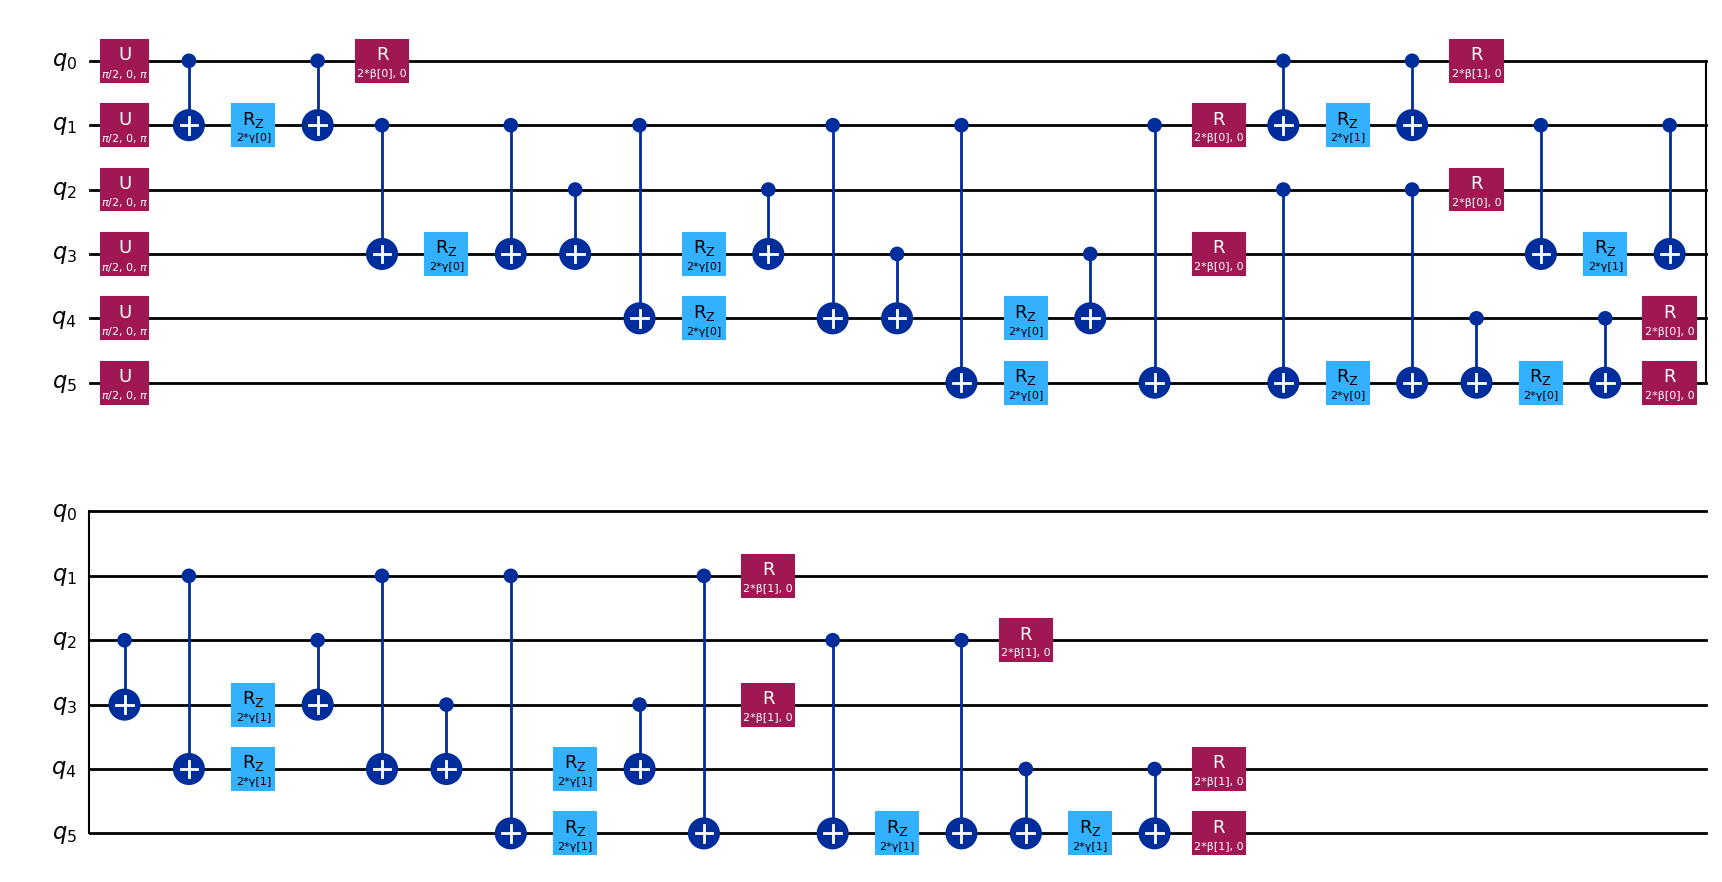

In [20]:
# Draw circuit
ansatz.decompose(reps=3).draw("mpl")

In [21]:
def cost_fn(params, ansatz, hamiltonian, estimator):


    # Input:
        # params: ndarray of (angle) parameters
        # ansatz: QuantumCircuit, the parameterized ansatz circuit
        # hamiltonian: SparsePauliOp, Hamiltonian to find the ground state of (linear combination of Pauli operators)
        # estimator: Estimator primitive to use

    # Return:
        # energy estimate (as a float)

    pub = (ansatz, hamiltonian, params)
    cost = estimator().run([pub]).result()[0].data.evs

    return cost

Initialize with a random set of parameter angles.

In [22]:
initial_params = 2 * np.pi * np.random.rand(ansatz.num_parameters)



Evaluate initial cost (using initial values).

In [23]:
# Our choice of estimator primitive
from qiskit.primitives import StatevectorEstimator as estimator

In [24]:
initial_cost = cost_fn(initial_params, ansatz, hamiltonian, estimator)
print("Initial cost:",initial_cost)

/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Initial cost: 1.3512420139803833


Next step is the actual optimization of the cost function. We use Scipy's minimize ([documentation here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)) with the "COBYLA" method.

In [25]:
from scipy.optimize import minimize

In [26]:
result = minimize(cost_fn, initial_params, args=(ansatz, hamiltonian, estimator), method="COBYLA")

/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


We look at the value of the cost function at the optimized parameters (returned by result.x) to get our estimate for the lowest eigenvalue of our Hamiltonian (or, in energy terms, the ground state).

In [27]:
eigenvalue = cost_fn(result.x, ansatz, hamiltonian, estimator)
print("Estimate for least eigenvalue:", eigenvalue)

Estimate for least eigenvalue: -4.117891647584089


As stated above, we need to transform this value slightly to obtain the estimated cut value.

Since we took a linear combination of Pauli operators made only of $I$ and $Z$, the eigenvectors of our Hamiltonian will be elements of the computational basis, i.e. a binary string. This will correspond to a partition of the vertices of $G$ with the two pieces taken as the indeces of the $0$s and $1$s respectively. Then, if one of the edges is $(i,j)$, then the corresponding Pauli string $Z_{ij}$ (as we took above) has eigenvalue $+1$ if the $i$-th and $j$-th bits agree, and $-1$ if they disagree. This corresponds respectively to not cutting the edge $(i,j)$ (since $i$ and $j$ are in the same piece of the partition) and cutting the edge (since $i$ and $j$ are in different pieces).

Taking the linear combination of the Pauli strings (i.e. edges of the graph) for our Hamiltonian as above, the eigenvalue $\lambda$ of a particular eigenvector (of the computational basis) is therefore given by
$$ \lambda =  \sum_{(i,j) \text{ not cut}}w_{ij} - \sum_{(i,j) \text{ cut}} w_{ij}.$$

Then, the least eigenvalue $\lambda$ corresponds to the largest value of $\sum_{(i,j) \text{ cut}} w_{ij}$ i.e. the maximum cut. Furthermore, we can easily obtain this from $\lambda$ as follows:
$$ \begin{aligned} & \frac{1}{2} \left( - \lambda + \sum_{(i,j) \text{ all edges}}w_{ij}\right) \\
&  =  \frac{1}{2} \left( \sum_{(i,j) \text{ cut}} w_{ij} - \sum_{(i,j) \text{ not cut}}w_{ij} + \sum_{(i,j) \text{ all edges}}w_{ij}\right) \\
& = \frac{1}{2}\left( 2 \sum_{(i,j) \text{ cut}} w_{ij} \right ) = \sum_{(i,j) \text{ cut}} w_{ij}.
  \end{aligned} $$



Note that our estimated least eigenvalue is essentially a weighted average of eigenvalues and so a slight overestimate for the ground state. Similarly, the resulting estimate for the cut value will always underestimate the actual maximum cut value.

In [28]:
est_max_cut = (-eigenvalue + sum(edge[2] for edge in edges))/2
print("Estimated Max-Cut:", est_max_cut)

Estimated Max-Cut: 6.058945823792044


Of course, the actual maximum cut of $G$ will be a sum of weights of edges, and we'd actually like to know the bipartition of vertices which achieves the maximum cut.

We can read off the bipartition from the (complementary pair of) eigenvectors corresponding to the minimum eigenvalue.

In [29]:
# Use a sampler to take readings from our circuit (with the optimized parameters)
from qiskit.primitives import StatevectorSampler as sampler

In [30]:
# Create a copy of our ansatz (using the fixed optimized parameters)
qc = ansatz.assign_parameters(result.x)

# Add measurements for us to read off
qc.measure_all()

job = sampler().run([qc], shots=1024)

In [31]:
# Get all the counts for each basis vector
counts = job.result()[0].data.meas.get_counts()
print(counts)

{'010101': 100, '010110': 224, '100101': 5, '100010': 14, '101010': 87, '101001': 205, '101100': 3, '111001': 45, '001010': 12, '011001': 15, '010111': 51, '101000': 49, '000111': 7, '110001': 13, '000110': 59, '011011': 1, '110101': 14, '111111': 3, '111101': 6, '000010': 10, '010001': 8, '001110': 8, '011101': 13, '011010': 3, '111011': 6, '101111': 1, '011000': 4, '100111': 6, '000100': 2, '110011': 4, '011111': 1, '101110': 6, '101011': 6, '010100': 5, '100011': 1, '000001': 3, '100110': 8, '010011': 5, '110000': 2, '111100': 1, '000000': 2, '000101': 1, '100100': 1, '111110': 1, '001101': 3}


The most commonly occuring eigenvectors are our candidates. As stated above, these come in complemenetary pairs (e.g. 00101 and 11010). For some graphs, there may be multiple partitions resulting in the same maximum cut value, leading to multiple eigenvectors with high counts.

In [32]:
# Extract the top candidates (which should come in complementary pairs).
# Note that some graphs contain multiple bipartitions with the same (or similar) cut value.
sorted_counts = sorted(counts.items(), key = lambda entry: entry[1], reverse = True)
print(sorted_counts[:8])

[('010110', 224), ('101001', 205), ('010101', 100), ('101010', 87), ('000110', 59), ('010111', 51), ('101000', 49), ('111001', 45)]


In [33]:
# Choose the top candidate as our eigenvector to determine the graph cut
eigenvector = sorted_counts[0][0]
print(eigenvector)

010110


Now we visualize the graph partition in question and calculate the corresponding cut value.

In [34]:
# Reverse the order since Qiskit indexes from right to left
partition = eigenvector[::-1]
print(partition)

011010


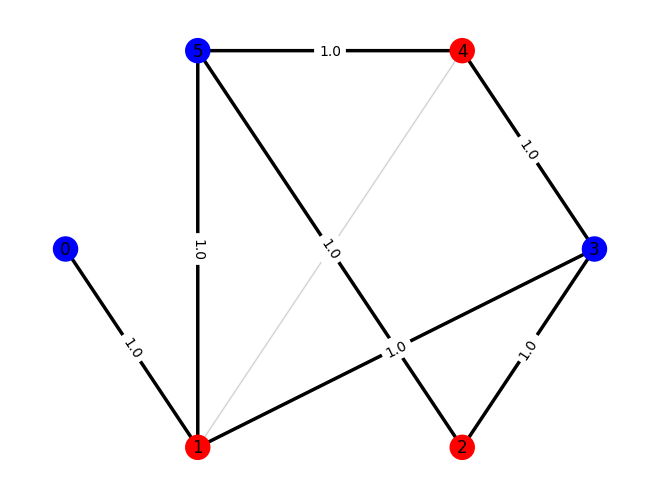

In [35]:
# Draw the graph for this cut
# Vertices in the bipartition coloured red and blue respectively
# Cut edges black and thicker, non-cut edges in light grey
mpl_draw(G, pos=rx.shell_layout(G), with_labels=True, edge_labels=str,
         node_color = ["b" if partition[i]=="0" else "r" for i in range(n)],
         edge_color = ["black" if partition[u] != partition[v] else "lightgrey" for u, v, _ in edges],
         width = [2.5 if partition[u] != partition[v] else 1.0 for u, v, _ in edges])

In [36]:
# Calculate actual cut value for this partition
cut_value = sum(adj_matrix[i,j] for i in range(n) for j in range(n) if partition[i]!=partition[j])
print("Cut value:", cut_value)

Cut value: 7.0


In [37]:
# For comparison, we recall the estimated max-cut from our optimization run above.
print("Estimated Max-Cut:", est_max_cut)

Estimated Max-Cut: 6.058945823792044


For relatively small graphs (for instance, with $n\leq 10$) we can use brute force to verify the maximum cut value. Note that the partition returned will be the first one that the algorithm finds, which may or may not coincide with the one we chose above if there are multiple optimal cuts.

In [38]:
import itertools

In [39]:
max_cut_value = float(0)
best_partition = None

# We iterate over partitions of the graph, identified with binary bitstrings of length n.
# WLOG we may assume that the first vertex 0 is labelled 0.

for bitstring in itertools.product([0,1], repeat = n-1):
  current_partition = (0,) + bitstring
  current_cut_value = sum(adj_matrix[i,j] for i in range(n) for j in range(n) if current_partition[i]!=current_partition[j])

  if current_cut_value > max_cut_value:
    max_cut_value = current_cut_value
    best_partition = current_partition

print("Winning partition:",best_partition)
print("Maximum Cut Value:", max_cut_value)

Winning partition: (0, 1, 1, 0, 1, 0)
Maximum Cut Value: 7.0


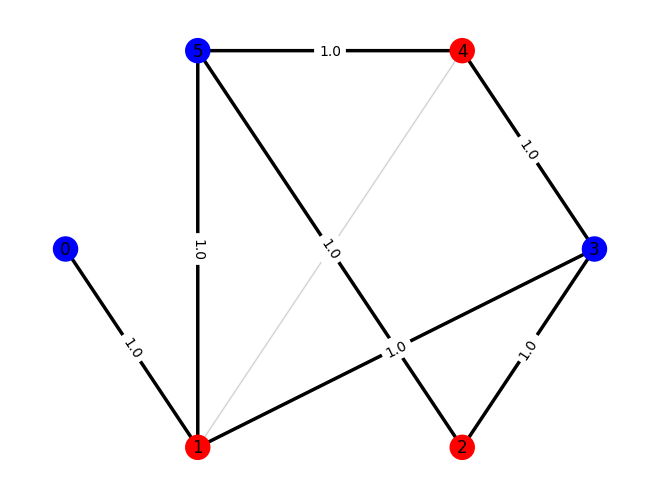

In [40]:
# Draw the graph for this optimal partition
mpl_draw(G, pos=rx.shell_layout(G), with_labels=True, edge_labels=str,
         node_color = ["b" if best_partition[i]==0 else "r" for i in range(n)],
         edge_color = ["black" if best_partition[u] != best_partition[v] else "lightgrey" for u, v, _ in edges],
         width = [2.5 if best_partition[u] != best_partition[v] else 1.0 for u, v, _ in edges])